# RDM benchmark — Random Dot Motion

Everything the paper reports for the random-dot-motion benchmark:

| Output | File |
|---|---|
| `RDM_bench.pdf` — accuracy, median RT and predictive NLL against coherence, every model against the human noise ceiling | `outputs/rdm/RDM_bench.pdf` |
| Table `tab:rdm_percoh` — Acc / RT / NLL / AUC / $\kappa$ per coherence | `outputs/rdm/rdm_percoh_table.tex` |
| Table `tab:rdm_global` — the same metrics pooled, with bootstrap CIs | `outputs/rdm/rdm_global_table.tex` |
| `LDA.pdf` — tercile LDA of the conditioning vector, one panel per learned parameter | `outputs/rdm/LDA.pdf` |
| Table `tab:rdm_mechanism` — per-coherence means of the learned drift / diffusion / threshold fields | `outputs/rdm/rdm_mechanism_table.tex` |

Models: **NRM**, **RTify**, **LNR**, **LBA**, **DDM** (the racing diffusion
model). Highlighting in both tables is computed here.

With `REFRESH = True` (or `REFRESH_WEIGHTS = True`) every output is written
with the `_REFRESH` suffix instead, next to the reference ones.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import warnings
warnings.filterwarnings('ignore')

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

# Canonical result layout (shared with ranking.ipynb), tables and figures.
from scripts import figures, results_io, tables
from scripts.results_io import save_global_results

OUTDIR = results_io.benchmark_dir('rdm')
OUTDIR.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [2]:
# Paths
DATA_CSV = ROOT / 'datasets' / 'rdm' / 'teddm_data.csv'
DATA_PKL = ROOT / 'datasets' / 'rdm' / 'rdm_nrm_dataset.pkl'
ME_EMBEDDINGS = ROOT / 'embeddings' / 'rdm' / 'rdm_embeddings.pt'
NRM_WEIGHT = ROOT / 'nrm' / 'weights' / 'NRM_rdm.pth'
RTIFY_HEAD = ROOT / 'competitors' / 'weights' / 'rdm' / 'rtify_head.pth'
RTIFY_STATES = ROOT / 'competitors' / 'weights' / 'rdm' / 'rtify_backbone_states.pth'

# REFRESH = True recomputes every prediction from the models instead of loading
# caches.  REFRESH_WEIGHTS = True evaluates the retrained weights (*_REFRESH.pth)
# and implies REFRESH.  Either flag adds a _REFRESH suffix to every output file,
# leaving the reference outputs untouched.
REFRESH = False
REFRESH_WEIGHTS = False

REFRESH = REFRESH or REFRESH_WEIGHTS
TAG = results_io.refresh_tag(REFRESH)
if REFRESH_WEIGHTS:
    # A model without its retrained weights is skipped; with none at all the
    # run stops here.
    NRM_WEIGHT, RTIFY_HEAD, RTIFY_STATES = (
        results_io.refresh_path(p, True) for p in (NRM_WEIGHT, RTIFY_HEAD, RTIFY_STATES))
    results_io.refresh_weights_available(
        {'NRM': [NRM_WEIGHT], 'RTify': [RTIFY_HEAD, RTIFY_STATES]})

NRM_CACHE = OUTDIR / f'nrm_predictions{TAG}.npz'
RTIFY_CACHE = OUTDIR / f'rtify_predictions{TAG}.npz'
COMP_CACHE = OUTDIR / f'classical_predictions{TAG}.npz'


def save_cache(path, **arrays):
    np.savez(path, **arrays)
    print(f'Cached to {path.name}')
    return path


COHERENCE_LIST = tables.RDM_COHERENCES     # 0.8 .. 51.2 %
COH_TO_IDX = {c: i for i, c in enumerate(COHERENCE_LIST)}
MODEL_ORDER = figures.RDM_MODEL_ORDER      # NRM, RTify, LNR, LBA, DDM

# RT samples drawn per trial.
N_RT_SAMPLES = 64
BATCH_SIZE = 256

# The seed that controls the SDE paths and the RTify draws.
SEED = 42

RT_MIN, RT_MAX = 0.05, 3.0

## 1. Load Data

The metadata pkl plus a single motion-energy embeddings `.pt`, re-ordered onto
the dataframe's `video_index` — the same path `scripts/train_nrm_rdm.py` takes,
so the split that trained the weights is the split evaluated here. If the pkl
is absent it is rebuilt from `teddm_data.csv`.

In [3]:
from datasets.rdm.loader import (
    build_rdm_nrm_dataset, load_rdm_nrm_dataset, rdm_collate_fn,
)
from torch.utils.data import DataLoader

if not DATA_PKL.exists():
    print(f'{DATA_PKL.name} not found — rebuilding it from {DATA_CSV.name}')
    build_rdm_nrm_dataset(csv_path=str(DATA_CSV), pkl_out=str(DATA_PKL))

dataset = load_rdm_nrm_dataset(
    pkl_out=DATA_PKL,
    embeddings_path=ME_EMBEDDINGS,
)
dataset.remove_rt_outliers_mad(mad_thresh=3.0, min_rt=RT_MIN, max_rt=RT_MAX)

train_ds, val_ds, test_ds = dataset.train_val_test_split(
    val_size=0.10, test_size=0.10, seed=42,
)
train_df = train_ds.df.copy()
test_df = test_ds.df.copy()

print(f'Train: {len(train_df)} | Test: {len(test_df)} trials')

test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    collate_fn=rdm_collate_fn, pin_memory=torch.cuda.is_available(),
)

Loading RDM metadata from datasets/rdm/rdm_nrm_dataset.pkl ...
Loading embeddings from embeddings/rdm/rdm_embeddings.pt ...
RT outlier removal (MAD per coherence, thresh=3.0, min_rt=0.05s, max_rt=3.0s): 3386 removed, 55052 remaining.
  train:  44161 trials
  val  :   5453 trials
  test :   5438 trials
Train: 44161 | Test: 5438 trials


## 2. NRM Predictions

In [4]:
from nrm.config import build_model
from scripts.eval_rdm import RDMEvaluator

nrm_model = nrm_data = None

if not NRM_WEIGHT.exists():
    print(f'Skipping NRM — missing weights: {NRM_WEIGHT.name}')
    print('The tables and figures below will omit the NRM row.')
else:
    # build_model('rdm') applies the RDM configuration from nrm/config.py.
    nrm_model = build_model('rdm', device=device)
    nrm_model.load_state_dict(torch.load(NRM_WEIGHT, map_location=device))
    nrm_model.eval()
    print(f'NRM loaded from {NRM_WEIGHT.name}')

    evaluator = RDMEvaluator(model=nrm_model, device=device, n_choices=2,
                             coherence_list=COHERENCE_LIST)

    if NRM_CACHE.exists() and not REFRESH:
        print(f'Loading NRM predictions from {NRM_CACHE.name}')
        _c = np.load(NRM_CACHE, allow_pickle=True)
        # The per-coherence pools are dicts.
        nrm_data = {k: (_c[k].item() if _c[k].shape == () else _c[k]) for k in _c.files}
    else:
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        nrm_data = evaluator.collect_predictions(test_loader,
                                                 n_rt_samples=N_RT_SAMPLES)
        save_cache(NRM_CACHE, **nrm_data)

NRM loaded from NRM_rdm.pth
Loading NRM predictions from nrm_predictions.npz


## 3. RTify Predictions

In [5]:
from competitors.rtify.rtify_model import RTifyModel, N_RT_POOL

# RTify scores pre-computed AlexNet+LSTM hidden states. Only the accumulator
# head is fitted to human RTs, so the backbone states are cached once — that
# cache is ~33 GB and is not shipped with the repo (see
# competitors/weights/rdm/README.md).
rtify_pred_choices = rtify_pred_rts = None
rtify_rt_by_coh = None

if RTIFY_CACHE.exists() and not REFRESH:
    print(f'Loading RTify predictions from {RTIFY_CACHE.name}')
    _c = np.load(RTIFY_CACHE, allow_pickle=True)
    rtify_pred_choices = _c['pred_choices']
    rtify_pred_rts = _c['pred_rts']
    if 'rt_samples_by_coh' in _c.files:
        rtify_rt_by_coh = _c['rt_samples_by_coh'].item()
else:
    if not RTIFY_STATES.exists():
        print(f'\nSkipping RTify — cached backbone states unavailable ({RTIFY_STATES.name}):')
        print(RTifyModel.missing_report())
        print('\nThe tables and figures below will omit the RTify row.')
    elif not RTIFY_HEAD.exists():
        print(f'\nSkipping RTify — missing weights: {RTIFY_HEAD.name}')
        print('Produce them with: python competitors/rtify/train_rdm.py')
        print('\nThe tables and figures below will omit the RTify row.')
    else:
        from competitors.rtify.rtify_model import COHERENCE_LIST as RTIFY_COH_DESC

        rtify = RTifyModel(device=device, head_path=RTIFY_HEAD)
        # (backbone_outputs_list, direction_list), both indexed by coherence in
        # RTify's own *descending* order.
        backbone_outputs, directions = RTifyModel.load_backbone_outputs(RTIFY_STATES)
        rtify_idx = {c: i for i, c in enumerate(RTIFY_COH_DESC)}

        rng = np.random.default_rng(SEED)
        choices = np.empty(len(test_df), dtype=np.int64)
        rts = np.empty(len(test_df), dtype=np.float64)
        rtify_rt_by_coh = {}
        for coh in COHERENCE_LIST:
            mask = test_df['coherence_str'].values == f'{coh:g}%'
            if not mask.any():
                continue
            i = rtify_idx[coh]
            ch, rt, pool = rtify.sample_onto_trials(
                backbone_outputs[i], directions[i],
                test_df['direction_label'].values[mask], rng,
                n_pool=N_RT_POOL)
            choices[mask] = ch
            rts[mask] = rt

            rtify_rt_by_coh[coh] = pool.tolist()

        rtify_pred_choices, rtify_pred_rts = choices, rts
        save_cache(RTIFY_CACHE, pred_choices=choices, pred_rts=rts,
                   rt_samples_by_coh=rtify_rt_by_coh)

Loading RTify predictions from rtify_predictions.npz


## 4. Classical Competitors (LNR / LBA / DDM)

In [6]:
from collections import defaultdict

from competitors import (
    prepare_data, fit_lnr, fit_lba, fit_ddm,
    simulate_lnr_with_samples, simulate_lba, simulate_ddm,
)


def rdm_to_competitor_df(df):
    # Rename RDM columns to the schema the classical fitters expect.
    out = df[['direction_label', 'human_choice', 'rt', 'correct', 'video_index']].copy()
    return out.rename(columns={
        'direction_label': 'stim', 'human_choice': 'response',
        'rt': 'resp_rt', 'video_index': 'image_index',
    })


def img_rt_pool_to_coh(rt_by_img):

    vid_to_coh = dict(zip(
        test_df['video_index'].astype(int),
        test_df['coherence_str'].map(lambda s: float(s.replace('%', ''))),
    ))
    by_coh = defaultdict(list)
    for vid, rts in rt_by_img.items():
        coh = vid_to_coh.get(int(vid))
        if coh is None:
            continue
        by_coh[coh].extend(rts if hasattr(rts, '__iter__') else [rts])
    return {k: np.asarray(v, dtype=float) for k, v in by_coh.items()}


if COMP_CACHE.exists() and not REFRESH:
    print(f'Loading cached classical predictions from {COMP_CACHE.name}')
    _c = np.load(COMP_CACHE, allow_pickle=True)
    lnr_pred_choices, lnr_pred_rts = _c['lnr_pred_choices'], _c['lnr_pred_rts']
    lba_pred_choices, lba_pred_rts = _c['lba_pred_choices'], _c['lba_pred_rts']
    ddm_pred_choices, ddm_pred_rts = _c['ddm_pred_choices'], _c['ddm_pred_rts']
    # savez stores a dict as a 0-d object array; .item() unwraps it.
    lnr_rt_by_coh = _c['lnr_rt_by_coh'].item()
    lba_rt_by_coh = _c['lba_rt_by_coh'].item()
    ddm_rt_by_coh = _c['ddm_rt_by_coh'].item()
else:
    test_comp = rdm_to_competitor_df(test_df)
    # prepare_data filters extreme RTs; it takes rt bounds, not n_choices.
    train_fit = prepare_data(rdm_to_competitor_df(train_df),
                             rt_min=RT_MIN, rt_max=RT_MAX)
    print(f'Competitor training data: {len(train_fit)} trials')

    # All three simulators share one signature —
    #   (params, test_data, n_choices, n_rt_samples, rng)
    #     -> (choices, rts, rt_samples_by_image)
    print('Fitting LNR...')
    lnr_result = fit_lnr(train_fit, n_choices=2)
    lnr_pred_choices, lnr_pred_rts, lnr_rt_by_img = simulate_lnr_with_samples(
        lnr_result.x, test_data=test_comp, n_choices=2,
        n_rt_samples=N_RT_SAMPLES, rng=np.random.default_rng(42))

    print('Fitting LBA...')
    lba_result = fit_lba(train_fit, n_choices=2)
    lba_pred_choices, lba_pred_rts, lba_rt_by_img = simulate_lba(
        lba_result.x, test_data=test_comp, n_choices=2,
        n_rt_samples=N_RT_SAMPLES, rng=np.random.default_rng(42))

    print('Fitting DDM (racing diffusion)...')
    ddm_result = fit_ddm(train_fit, n_choices=2)
    ddm_pred_choices, ddm_pred_rts, ddm_rt_by_img = simulate_ddm(
        ddm_result.x, test_data=test_comp, n_choices=2,
        n_rt_samples=N_RT_SAMPLES, rng=np.random.default_rng(42))

    lnr_rt_by_coh = img_rt_pool_to_coh(lnr_rt_by_img)
    lba_rt_by_coh = img_rt_pool_to_coh(lba_rt_by_img)
    ddm_rt_by_coh = img_rt_pool_to_coh(ddm_rt_by_img)

    save_cache(COMP_CACHE,
               lnr_pred_choices=lnr_pred_choices, lnr_pred_rts=lnr_pred_rts,
               lba_pred_choices=lba_pred_choices, lba_pred_rts=lba_pred_rts,
               ddm_pred_choices=ddm_pred_choices, ddm_pred_rts=ddm_pred_rts,
               lnr_rt_by_coh=lnr_rt_by_coh, lba_rt_by_coh=lba_rt_by_coh,
               ddm_rt_by_coh=ddm_rt_by_coh)

print('RT pool sizes (LBA):', {k: len(v) for k, v in sorted(lba_rt_by_coh.items())})

Loading cached classical predictions from classical_predictions.npz
RT pool sizes (LBA): {0.8: 49920, 1.6: 50048, 3.2: 49472, 6.4: 49664, 12.8: 49664, 25.6: 49280, 51.2: 49984}


## 5. Per-Trial Index Arrays

In [7]:
coh_strs = test_df['coherence_str'].values
coh_float_arr = np.array([float(c.replace('%', '')) for c in coh_strs])
coh_idx_arr = np.array([COH_TO_IDX[c] for c in coh_float_arr])
human_choices = test_df['human_choice'].values.astype(int)
true_labels = test_df['direction_label'].values.astype(int)
human_rts = test_df['rt'].values.astype(float)
sub_ids = test_df['subID'].values.astype(str)

PREDICTIONS = {}
if nrm_data is not None:
    PREDICTIONS['NRM'] = dict(choices=nrm_data['pred_choices'], rts=nrm_data['pred_rts'],
                              rt_pool=nrm_data['rt_samples_by_coh'],
                              probs_by_coh=nrm_data['pred_probs_by_coh'])
PREDICTIONS.update({
    'LNR': dict(choices=lnr_pred_choices, rts=lnr_pred_rts,
                rt_pool=lnr_rt_by_coh),
    'LBA': dict(choices=lba_pred_choices, rts=lba_pred_rts,
                rt_pool=lba_rt_by_coh),
    'DDM': dict(choices=ddm_pred_choices, rts=ddm_pred_rts,
                rt_pool=ddm_rt_by_coh),
})
if rtify_pred_choices is not None:
    PREDICTIONS['RTify'] = dict(choices=rtify_pred_choices, rts=rtify_pred_rts,
                                rt_pool=rtify_rt_by_coh)

print(f'Test set: {len(test_df)} trials, {len(COHERENCE_LIST)} coherence '
      f'levels, {len(np.unique(sub_ids))} subjects')
print('Models with predictions:', ', '.join(k for k in MODEL_ORDER if k in PREDICTIONS))


def roster_caveat():
    absent = [k for k in MODEL_ORDER if k not in PREDICTIONS]
    if not absent:
        return ''
    return ('[INCOMPLETE ROSTER] bold/underline rank only the models present. '
            f'Missing: {", ".join(absent)}. '
            'Produce them before using this table.\n')

Test set: 5438 trials, 7 coherence levels, 21 subjects
Models with predictions: NRM, RTify, LNR, LBA, DDM


## 6. Metrics

Per coherence, for every model: accuracy against ground truth, median RT,
the negative log-likelihood of the human RTs under a KDE fitted to the model's
RT samples, AUC and Cohen's $\kappa$. The human noise ceiling uses the same
definitions, with leave-one-trial-out KDE for its NLL.

The global values are the means over the seven coherence levels, plus
$r_{\rm RT}$ — the correlation between the model's and the humans'
per-coherence median RT. The *Avg* column of the per-coherence table and the
global table therefore carry the same number by construction.

In [8]:
from metrics.point_metrics import safe_auc, safe_kappa
from metrics.relational_metrics import split_half_rt_nc
from metrics.rt_likelihood import kde_nll, kde_nll_pertrial, loto_nll
from scripts.eval_rdm import NLL_RT_RANGE


def _probs_for(spec, coh, mask):
    by_coh = spec.get('probs_by_coh')
    if by_coh is not None:
        p = np.asarray(by_coh.get(coh, []), dtype=float)
        if len(p) == int(mask.sum()):
            return p
    return np.asarray(spec['choices'], dtype=float)[mask]


def _rt_pool_for(spec, coh, mask):
    pool = spec.get('rt_pool')
    if pool is not None and coh in pool:
        return np.asarray(pool[coh], dtype=float)
    return np.asarray(spec['rts'], dtype=float)[mask]


def per_coherence_metrics(spec):
    # {coherence: {Acc, RT (ms), NLL, AUC, kappa}} plus the per-trial NLL terms.
    out, nll_terms = {}, []
    for coh in COHERENCE_LIST:
        mask = coh_float_arr == coh
        if mask.sum() == 0:
            continue
        t_lb = true_labels[mask]
        p_ch = np.asarray(spec['choices'])[mask]
        p_rt = np.asarray(spec['rts'], dtype=float)[mask]
        h_rt = human_rts[mask]
        pool = _rt_pool_for(spec, coh, mask)
        pool = pool[np.isfinite(pool)]

        out[coh] = dict(
            Acc=float(np.mean(p_ch == t_lb)),
            RT=float(np.median(p_rt)) * 1000.0,
            NLL=kde_nll(h_rt, pool, rt_range=NLL_RT_RANGE),
            AUC=safe_auc(t_lb, _probs_for(spec, coh, mask)),
            kappa=safe_kappa(t_lb, p_ch),
        )
        nll_terms.extend(kde_nll_pertrial(h_rt, pool, rt_range=NLL_RT_RANGE).tolist())
    return out, np.asarray(nll_terms, dtype=float)


def human_per_coherence_metrics():
    out = {}
    for coh in COHERENCE_LIST:
        mask = coh_float_arr == coh
        if mask.sum() == 0:
            continue
        t_lb, h_ch, h_rt = true_labels[mask], human_choices[mask], human_rts[mask]
        out[coh] = dict(
            Acc=float(np.mean(h_ch == t_lb)),
            RT=float(np.median(h_rt)) * 1000.0,
            NLL=loto_nll(h_rt, rt_range=NLL_RT_RANGE),
            AUC=safe_auc(t_lb, h_ch.astype(float)),
            kappa=safe_kappa(t_lb, h_ch),
        )
    return out


def _mean(vals):
    v = [x for x in vals if np.isfinite(x)]
    return float(np.mean(v)) if v else float('nan')


per_coh, nll_terms = {}, {}
for name in MODEL_ORDER:
    if name not in PREDICTIONS:
        continue
    print(f'Computing {name} metrics ...')
    per_coh[name], nll_terms[name] = per_coherence_metrics(PREDICTIONS[name])

human_per_coh = human_per_coherence_metrics()
human_rt_curve = [human_per_coh[c]['RT'] for c in COHERENCE_LIST if c in human_per_coh]

globals_ = {}
for name, pc in per_coh.items():
    cohs = [c for c in COHERENCE_LIST if c in pc]
    model_rt_curve = [pc[c]['RT'] for c in cohs]
    r_rt = (float(pearsonr(model_rt_curve, human_rt_curve)[0])
            if len(cohs) >= 3 and np.std(model_rt_curve) > 0 else float('nan'))
    terms = nll_terms[name][np.isfinite(nll_terms[name])]
    globals_[name] = {
        'Acc': _mean([pc[c]['Acc'] for c in cohs]),
        'AUC': _mean([pc[c]['AUC'] for c in cohs]),
        'kappa': _mean([pc[c]['kappa'] for c in cohs]),
        'r_RT': r_rt,
        'NLL': _mean([pc[c]['NLL'] for c in cohs]),
        'NLL_sem': (float(np.std(terms, ddof=1) / np.sqrt(len(terms)))
                    if len(terms) > 1 else float('nan')),
    }

# r_RT noise ceiling: split-half across trials (the humans' own reliability).
hh_r_rt, _ = split_half_rt_nc(coh_float_arr, human_rts, COHERENCE_LIST)
human_global = {
    'Acc': _mean([human_per_coh[c]['Acc'] for c in COHERENCE_LIST if c in human_per_coh]),
    'AUC': _mean([human_per_coh[c]['AUC'] for c in COHERENCE_LIST if c in human_per_coh]),
    'kappa': _mean([human_per_coh[c]['kappa'] for c in COHERENCE_LIST if c in human_per_coh]),
    'r_RT': float(hh_r_rt),
    'NLL': _mean([human_per_coh[c]['NLL'] for c in COHERENCE_LIST if c in human_per_coh]),
}

print('\nGlobal values')
print(f"  {'model':8s} {'Acc':>7s} {'AUC':>7s} {'kappa':>7s} {'r_RT':>7s} {'NLL':>8s}")
for name, g in [('Human', human_global)] + [(n, globals_[n]) for n in MODEL_ORDER
                                            if n in globals_]:
    print(f"  {name:8s} {g['Acc']:7.3f} {g['AUC']:7.3f} {g['kappa']:7.3f} "
          f"{g['r_RT']:7.3f} {g['NLL']:8.3f}")

Computing NRM metrics ...
Computing RTify metrics ...
Computing LNR metrics ...
Computing LBA metrics ...
Computing DDM metrics ...

Global values
  model        Acc     AUC   kappa    r_RT      NLL
  Human      0.689   0.690   0.379   0.971   -0.204
  NRM        0.794   0.924   0.585   0.989   -0.147
  RTify      0.548   0.548   0.095   0.821   -0.067
  LNR        0.482   0.482  -0.036  -0.547   -0.121
  LBA        0.505   0.505   0.010   0.497   -0.117
  DDM        0.501   0.502   0.003  -0.720   -0.122


## 7. Bootstrap confidence intervals

95 % intervals from B = 1000 resamples of the test **trials**, re-aggregated
per coherence exactly as the point estimates are.

In [9]:
cis = {}
for name in MODEL_ORDER:
    if name not in PREDICTIONS:
        continue
    spec = PREDICTIONS[name]
    # Per-trial score array, aligned with test_df, for the AUC inside the loop.
    probs = np.asarray(spec['choices'], dtype=float).copy()
    if spec.get('probs_by_coh') is not None:
        for coh in COHERENCE_LIST:
            mask = coh_float_arr == coh
            p = np.asarray(spec['probs_by_coh'].get(coh, []), dtype=float)
            if len(p) == int(mask.sum()):
                probs[mask] = p

    print(f'  bootstrapping {name} (B=1000) ...')
    cis[name] = tables.bootstrap_choice_rt_cis(
        level_values=coh_float_arr,
        true_labels=true_labels,
        pred_choices=np.asarray(spec['choices']),
        pred_probs=probs,
        human_rts=human_rts,
        pred_rts=np.asarray(spec['rts'], dtype=float),
        levels=COHERENCE_LIST,
        auc_fn=safe_auc,
        kappa_fn=safe_kappa,
        B=1000, seed=42,
    )
    cis[name]['NLL_sem'] = globals_[name]['NLL_sem']
print('Done.')

  bootstrapping NRM (B=1000) ...
  bootstrapping RTify (B=1000) ...
  bootstrapping LNR (B=1000) ...
  bootstrapping LBA (B=1000) ...
  bootstrapping DDM (B=1000) ...
Done.


## 8. Table `tab:rdm_percoh`

In [10]:
percoh_tex = tables.rdm_per_coherence_table(
    per_coh, human_per_coh, levels=COHERENCE_LIST,
    avg=globals_, human_avg=human_global,
)
(OUTDIR / f'rdm_percoh_table{TAG}.tex').write_text(percoh_tex)
print(roster_caveat() + percoh_tex)
print(f"\nSaved -> {(OUTDIR / f'rdm_percoh_table{TAG}.tex').relative_to(ROOT)}")

\begin{table}[t]
  \centering
  \caption{RDM task: per-coherence model comparison. RT: median (ms). NLL: negative log-likelihood (lower is better). AUC: area under ROC curve grouped by coherence. $\kappa$: Cohen\textquotesingle s kappa. \textit{Avg}: mean over the 7 coherence levels, for every row (identical to the global table). Human~(NC): noise ceiling (AUC/$\kappa$ vs.~ground-truth labels; NLL = LOTO). Superscript grey values give $|\Delta|$ from Human~(NC). \textbf{Bold} = best, \underline{underline} = second best per column (smallest $|\Delta|$, lowest value for NLL; Human~(NC) excluded).}
  \label{tab:rdm_percoh}
  \scriptsize
  \setlength{\tabcolsep}{3pt}
  \resizebox{\linewidth}{!}{%
  \begin{tabular}{@{} ll ccccccc c @{}}
    \toprule
    & & \multicolumn{7}{c}{\textbf{Coherence Levels (\%)}} & \\
    \cmidrule(lr){3-9}
    \textbf{Model} & \textbf{Metric} & 0.8 & 1.6 & 3.2 & 6.4 & 12.8 & 25.6 & 51.2 & \textit{Avg} \\
    \midrule
    \multirow{5}{*}{\begin{tabular}[c]{@{}l@{

## 9. Table `tab:rdm_global`

In [11]:
global_tex = tables.rdm_global_table(globals_, human_global, cis)
(OUTDIR / f'rdm_global_table{TAG}.tex').write_text(global_tex)
print(roster_caveat() + global_tex)
print(f"\nSaved -> {(OUTDIR / f'rdm_global_table{TAG}.tex').relative_to(ROOT)}")

\begin{table}[t]
  \centering
  \caption{%
    RDM task. Choice performance is measured by Acc, AUC, and Cohen's~$\kappa$
    ($\kappa_{\mathrm{acc}}$); RT alignment by $r_{\rm RT}$; and RT distribution
    fit by NLL.
    \textbf{Bold} = best; \underline{underline} = second best (relative to NC,
    or absolute for NLL and $r_{\rm RT}$).
    Asymmetric 95\% CIs (bootstrap, $B{=}1000$) shown as superscripts/subscripts;
    NLL reports $\pm$ Std. Error of the Mean.
  }
  \label{tab:rdm_global}
  \footnotesize
  \setlength{\tabcolsep}{5pt}
  \renewcommand{\arraystretch}{1.4}
  \resizebox{.85\linewidth}{!}{%
  \begin{tabular}{@{} l ccc cc @{}}
    \toprule
    & \multicolumn{3}{c}{\textbf{Choice}}
    & \multicolumn{2}{c}{\textbf{RT}} \\
    \cmidrule(lr){2-4} \cmidrule(lr){5-6}
    \textbf{Model}
      & Acc ($|\Delta|\!\downarrow$)
      & AUC ($|\Delta|\!\downarrow$)
      & $\kappa_{\mathrm{acc}}$ ($|\Delta|\!\downarrow$)
      & $r_{\rm RT}$ ($\uparrow$)
      & NLL ($\downarrow$) \\

## 10. Figure — `RDM_bench.pdf`

Three panels against coherence: the psychometric function, the chronometric
function and the predictive NLL. The human band is $\pm 1$ standard deviation
across subjects.

Saved -> outputs/rdm/RDM_bench.pdf


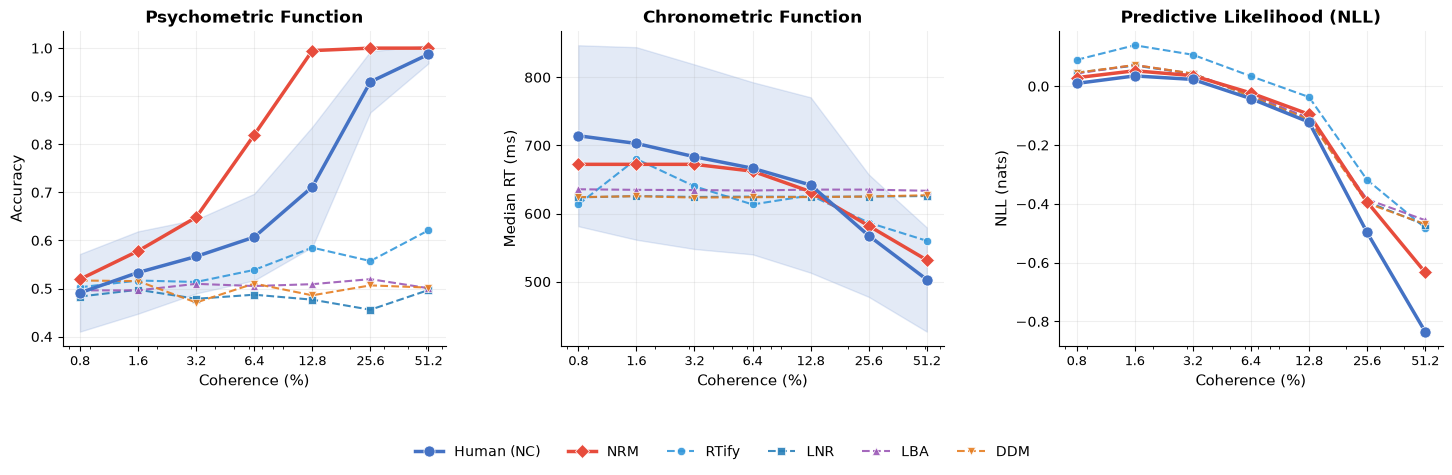

In [12]:
# Per-subject curves give the human band its width.
subjects = np.unique(sub_ids)
acc_by_sub = np.full((len(subjects), len(COHERENCE_LIST)), np.nan)
rt_by_sub = np.full((len(subjects), len(COHERENCE_LIST)), np.nan)
for si, s in enumerate(subjects):
    for ci, coh in enumerate(COHERENCE_LIST):
        m = (sub_ids == s) & (coh_float_arr == coh)
        if m.sum() >= 1:
            acc_by_sub[si, ci] = np.mean(human_choices[m] == true_labels[m])
            rt_by_sub[si, ci] = np.median(human_rts[m]) * 1000.0

human_bands = {
    'Acc': np.nanstd(acc_by_sub, axis=0),
    'RT': np.nanstd(rt_by_sub, axis=0),
}

fig = figures.plot_rdm_bench(
    per_coh, human_per_coh, COHERENCE_LIST,
    save_path=OUTDIR / f'RDM_bench{TAG}.pdf',
    human_bands=human_bands,
)
plt.show()

## 11. Difficulty–parameter correlation — `LDA.pdf` and `tab:rdm_mechanism`

The NRM never receives the coherence label: it is conditioned only on the
motion-energy embedding. Grouping the learned drift, diffusion and threshold
fields by coherence therefore shows what the encoder recovers from the video
alone, and the tercile LDA shows that the conditioning vector is organised by
those same quantities.

\begin{center}\small
\begin{tabular}{lcccccc}
\toprule
Coh.\ (\%) & drift $\lVert f\rVert$ & contrast $f^{+}\!-\!f^{-}$ & diffusion $\lVert g\rVert$ & threshold $\theta$ & SNR contrast & SNR mag. \\
\midrule
  0.8  & 0.999 & 0.029 & 0.3961 & 0.532 & 0.074 & 2.520 \\
  1.6  & 1.001 & 0.030 & 0.3961 & 0.532 & 0.075 & 2.526 \\
  3.2  & 1.004 & 0.103 & 0.3960 & 0.532 & 0.260 & 2.535 \\
  6.4  & 1.012 & 0.222 & 0.3960 & 0.532 & 0.562 & 2.555 \\
 12.8  & 1.037 & 0.367 & 0.3960 & 0.532 & 0.929 & 2.617 \\
 25.6  & 1.087 & 0.611 & 0.3959 & 0.532 & 1.545 & 2.745 \\
 51.2  & 1.206 & 0.976 & 0.3957 & 0.533 & 2.468 & 3.046 \\
\bottomrule
\end{tabular}
\end{center}
[saved] outputs/rdm/LDA.pdf
        param  cv_acc  cv_acc_std  chance  evr_LD1  evr_LD2
    drift_mag  0.7600      0.0151  0.3333   0.9342   0.0658
diffusion_mag  0.5833      0.0201  0.3333   0.9225   0.0775
    threshold  0.6918      0.0092  0.3333   0.8590   0.1410


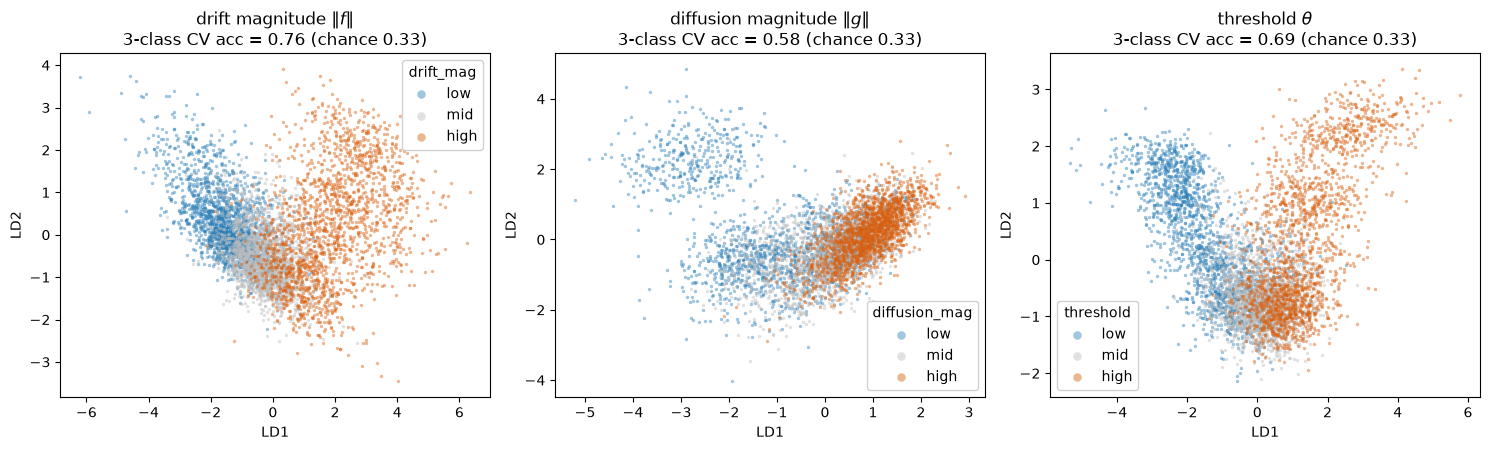

In [13]:
from scripts.difficulty_parameter_correlation import extract_parameters, plot_lda2d

if nrm_model is None:
    # An NRM-only analysis; the run is failed at the end of the notebook,
    # once the other models' results are saved.
    print(f'Skipping the mechanism analysis — it needs NRM ({NRM_WEIGHT.name} missing).')
else:
    # Re-reads the test split the same way (same seed, same outlier rule), and
    # evaluates f, g and h on the SDE grid.
    mech_df, cond_bar = extract_parameters(nrm_model, test_ds)
    mech_df.to_csv(OUTDIR / f'rdm_mechanism_per_trial{TAG}.csv', index=False)

    mech_tex = tables.rdm_mechanism_table(mech_df)
    (OUTDIR / f'rdm_mechanism_table{TAG}.tex').write_text(mech_tex)
    print(mech_tex)

    fig_lda, lda_stats = plot_lda2d(mech_df, cond_bar, save_path=OUTDIR / f'LDA{TAG}.pdf',
                                    stats_path=OUTDIR / f'mechanism_lda2d_stats{TAG}.csv')
    plt.show()

## 12. Save Results

In [14]:
# ranking.ipynb reads nll_mean / acc / auc / kappa / r_RT per model, so the
# keys it expects are written here alongside the human noise ceiling.
ranking_payload = {
    name: {'global': {'acc': g['Acc'], 'auc': g['AUC'], 'kappa': g['kappa'],
                      'r_RT': g['r_RT'], 'nll_mean': g['NLL']}}
    for name, g in globals_.items()
}
ranking_payload['Human (NC)'] = {'global': {
    'acc': human_global['Acc'], 'auc': human_global['AUC'],
    'kappa': human_global['kappa'], 'r_RT': human_global['r_RT'],
    'nll_mean': human_global['NLL'],
}}
path = save_global_results('rdm', ranking_payload, refresh=REFRESH)
print(f'Results written to {path.relative_to(ROOT)}')

for name in (f'RDM_bench{TAG}.pdf', f'LDA{TAG}.pdf', f'rdm_percoh_table{TAG}.tex',
             f'rdm_global_table{TAG}.tex', f'rdm_mechanism_table{TAG}.tex'):
    p = OUTDIR / name
    print(f"{'OK  ' if p.exists() else 'MISS'} {p.relative_to(ROOT)}")

print('\nNext: run pipelines/sc.ipynb, then pipelines/ranking.ipynb.')

if nrm_model is None:
    raise FileNotFoundError(
        f'{results_io.display_path(NRM_WEIGHT)} is missing, so the NRM-only '
        'mechanism analysis (LDA.pdf, tab:rdm_mechanism) was not produced; the '
        'results of the other models are saved above. Train NRM with '
        'scripts/train_nrm_rdm.py.')

Results written to outputs/rdm/rdm_global_results.json
OK   outputs/rdm/RDM_bench.pdf
OK   outputs/rdm/LDA.pdf
OK   outputs/rdm/rdm_percoh_table.tex
OK   outputs/rdm/rdm_global_table.tex
OK   outputs/rdm/rdm_mechanism_table.tex

Next: run pipelines/sc.ipynb, then pipelines/ranking.ipynb.
